In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
def collatz_routine(n: int) -> list[int]:
    """Return the every steps of number 'n'. """
    collatz = [n]

    while n != 1:
        
        if n % 2 == 0:    # even
            n = int(n/2)
        elif n % 2 == 1:  # odd
            n = int( (n*3 + 1) / 2 )

        collatz.append(n)

    return collatz


In [3]:
def tree_angles(routine: list[int], root_angle, even_angle, odd_angle) -> list[float]:
    """
    Example:
        input:  [ 1,  2,  4,  8,  5, 10, 20, 13, 26, 17, 11,  7]
        output: [ 0,  5, 10,  5, 10, 15, 10, 15, 10,  5,  0]
    """
    angles = [root_angle]

    for i in range(2, len(routine)):
        angle = angles[i-2]
        if routine[i] % 2 == 0:
            angle += even_angle
        else:
            angle += odd_angle
        angles.append(angle)

    return angles

In [15]:
class Link:
    def __init__(self, start, end, angle):
        self.start = start
        self.end = end
        self.weight = 1
        self.angle = angle

    def increase_weight(self):
        if self.weight < 10:
            self.weight += 1

    def coordinates(self, x1, y1):
        self.x1 = x1
        self.y1 = y1
        self.x2 = x1 + np.cos(self.angle * np.pi / 180)
        self.y2 = y1 + np.sin(self.angle * np.pi / 180)
        
    def __eq__(self, other):
        return self.start == other.start and self.end == other.end



def collatz_tree(
    max: int, root_angle: float = 90, even_angle: float = -5, odd_angle: float = 5, 
) -> list:
    """Draw a Collatz tree"""

    # list for store all links
    links = []

    for n in range(2, max+1):

        # calculate Collatz routine
        routine = collatz_routine(n)
        routine.reverse()
        angles = tree_angles(routine, root_angle, even_angle, odd_angle)

        # append a new link
        for i in range(len(routine)-1):

            link = Link(routine[i], routine[i + 1], angles[i])

            if link in links:
                existing_link = links[links.index(link)]
                existing_link.increase_weight()
            else:
                links.append(link)

    return links


def plot_trees(links: list[Link]) -> None:

    for link in links:
        if link.start == 1:
            link.coordinates(0, 0)

        else:
            for other_link in links:
                if link.start == other_link.end:
                    link.coordinates(other_link.x2, other_link.y2)
                    break

        
        plt.axis("equal")
        plt.axis("off")
        plt.plot([link.x1, link.x2], 
                 [link.y1, link.y2], 
                 "g-", 
                 linewidth=2, 
                 alpha=link.weight/10)





start plotting...


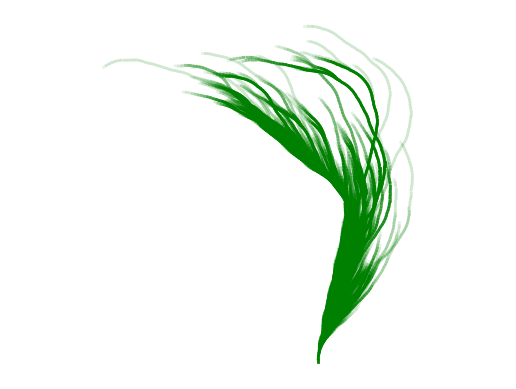

In [ ]:
trees = collatz_tree(5000)
print("start plotting...")
plot_trees(trees)
